# Импорт библиотек

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import config

# Загрузка датасета

In [2]:
books = pd.read_csv(config.AMAZON_BOOKS_TABLE_PATHS['books'], encoding="latin-1")
ratings = pd.read_csv(
    config.AMAZON_BOOKS_TABLE_PATHS["ratings"],
    encoding="latin-1",
    usecols=["Id", "Title", "User_id", "review/score", "review/time"],
    dtype={
        "Id": "string",
        "Title": "string",
        "User_id": "string",
        "review/score": "float32",
        "review/time": "int64",
    },
)
#users = pd.read_csv(config.AMAZON_BOOKS_TABLE_PATHS['users'], encoding="latin-1")

In [3]:
books.head()

,Title,description,authors,image,previewLink,publisher,publishedDate,infoLink,categories,ratingsCount
0,Its Only Art If Its Well Hung!,NaN,['Julie Strain'],http://books.google.com/books/content?id=DykPA...,http://books.google.nl/books?id=DykPAAAACAAJ&d...,NaN,1996,http://books.google.nl/books?id=DykPAAAACAAJ&d...,['Comics & Graphic Novels'],NaN
1,Dr. Seuss: American Icon,Philip Nel takes a fascinating look into the k...,['Philip Nel'],http://books.google.com/books/content?id=IjvHQ...,http://books.google.nl/books?id=IjvHQsCn_pgC&p...,A&C Black,2005-01-01,http://books.google.nl/books?id=IjvHQsCn_pgC&d...,['Biography & Autobiography'],NaN
2,Wonderful Worship in Smaller Churches,This resource includes twelve principles in un...,['David R. Ray'],http://books.google.com/books/content?id=2tsDA...,http://books.google.nl/books?id=2tsDAAAACAAJ&d...,NaN,2000,http://books.google.nl/books?id=2tsDAAAACAAJ&d...,['Religion'],NaN
3,Whispers of the Wicked Saints,Julia Thomas finds her life spinning out of co...,['Veronica Haddon'],http://books.google.com/books/content?id=aRSIg...,http://books.google.nl/books?id=aRSIgJlq6JwC&d...,iUniverse,2005-02,http://books.google.nl/books?id=aRSIgJlq6JwC&d...,['Fiction'],NaN
4,"Nation Dance: Religion, Identity and Cultural ...",NaN,['Edward Long'],NaN,http://books.google.nl/books?id=399SPgAACAAJ&d...,NaN,2003-03-01,http://books.google.nl/books?id=399SPgAACAAJ&d...,NaN,NaN


In [4]:
books.info()

<class 'pandas.DataFrame'>
RangeIndex: 212404 entries, 0 to 212403
Data columns (total 10 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   Title          212403 non-null  str    
 1   description    143962 non-null  str    
 2   authors        180991 non-null  str    
 3   image          160329 non-null  str    
 4   previewLink    188568 non-null  str    
 5   publisher      136518 non-null  str    
 6   publishedDate  187099 non-null  str    
 7   infoLink       188568 non-null  str    
 8   categories     171205 non-null  str    
 9   ratingsCount   49752 non-null   float64
dtypes: float64(1), str(9)
memory usage: 16.2 MB


In [5]:
ratings.head()

,Id,Title,User_id,review/score,review/time
0,1882931173,Its Only Art If Its Well Hung!,AVCGYZL8FQQTD,4.0,940636800
1,0826414346,Dr. Seuss: American Icon,A30TK6U7DNS82R,5.0,1095724800
2,0826414346,Dr. Seuss: American Icon,A3UH4UZ4RSVO82,5.0,1078790400
3,0826414346,Dr. Seuss: American Icon,A2MVUWT453QH61,4.0,1090713600
4,0826414346,Dr. Seuss: American Icon,A22X4XUPKF66MR,4.0,1107993600


In [6]:
ratings.info()

<class 'pandas.DataFrame'>
RangeIndex: 3000000 entries, 0 to 2999999
Data columns (total 5 columns):
 #   Column        Dtype  
---  ------        -----  
 0   Id            string 
 1   Title         string 
 2   User_id       string 
 3   review/score  float32
 4   review/time   int64  
dtypes: float32(1), int64(1), string(3)
memory usage: 103.0 MB


# Пропущенные значения

In [7]:
total_na_books = books.isna().sum().rename("Total NaN")
ratio_na_books = (total_na_books / len(books)).rename("Ratio NaN")
non_na_books = (len(books) - total_na_books).rename("Non NaN")

pd.concat([total_na_books, ratio_na_books, non_na_books], axis=1)

,Total NaN,Ratio NaN,Non NaN
Title,1,0.000005,212403
description,68442,0.322226,143962
authors,31413,0.147893,180991
image,52075,0.245170,160329
previewLink,23836,0.112220,188568
publisher,75886,0.357272,136518
publishedDate,25305,0.119136,187099
infoLink,23836,0.112220,188568
categories,41199,0.193965,171205
ratingsCount,162652,0.765767,49752


In [8]:
total_na_ratings = ratings.isna().sum().rename("Total NaN")
ratio_na_ratings = (total_na_ratings / len(ratings)).rename("Ratio NaN")
non_na_ratings = (len(ratings) - total_na_ratings).rename("Non NaN")

pd.concat([total_na_ratings, ratio_na_ratings, non_na_ratings], axis=1)

,Total NaN,Ratio NaN,Non NaN
Id,0,0.000000,3000000
Title,208,0.000069,2999792
User_id,561787,0.187262,2438213
review/score,0,0.000000,3000000
review/time,0,0.000000,3000000


## Выводы
Итого у нас $143962$ **описания книг** и около $3$ **млн оценок**. Этого должно хватить для качественной оценки и возможного обучения

# Предобработка

In [9]:
import ast
import re

def parse_list_string(val):
    if pd.isna(val):
        return []
    try:
        return ast.literal_eval(val)
    except (ValueError, SyntaxError):
        return [str(val).strip("[]'\"")]

books['categories_list'] = books['categories'].apply(parse_list_string)
books['authors_list'] = books['authors'].apply(parse_list_string)

# Извлекаем ПЕРВЫЙ жанр как основной (для упрощения модели USER_GENRE / BOOK_GENRE)
books['primary_genre'] = books['categories_list'].apply(lambda x: x[0].strip() if len(x) > 0 else 'Unknown')

# Нормализация: нижний регистр и удаление лишних пробелов (как требуется в README)
books['primary_genre'] = books['primary_genre'].str.lower().str.strip()
books['authors_list'] = books['authors_list'].apply(lambda lst: [author.lower().strip() for author in lst])

# Название используется только для присоединения метаданных, не как ID книги.
# Пустые названия не должны совпадать друг с другом при merge.
for table in (books, ratings):
    table['clean_title'] = (
        table['Title'].astype('string').str.lower().str.strip().replace('', pd.NA)
    )

In [10]:
books['embedding_text'] = books.apply(
    lambda row: f"{row['Title']}. {row['description']}" if pd.notna(row['description']) else f"Book titled: {row['Title']}. Category: {row['primary_genre']}",
    axis=1
)

print(f"Пропусков в embedding_text: {books['embedding_text'].isna().sum()}")

Пропусков в embedding_text: 0


In [11]:
# Исходную ratings сохраняем для EDA. Для модели нужна одна оценка на user–Id.
ratings_valid = ratings.dropna(subset=['User_id', 'Id']).copy()
ratings_valid = ratings_valid[
    ratings_valid['review/score'].between(1, 5)
].copy()

# Если пользователь оценивал тот же Id несколько раз, оставляем последнюю оценку.
# При одинаковом времени оставляем последнюю строку исходного файла.
n_before_dedup = len(ratings_valid)
ratings_valid = (
    ratings_valid.sort_values('review/time', kind='stable')
    .drop_duplicates(subset=['User_id', 'Id'], keep='last')
    .copy()
)
timestamps = ratings_valid["review/time"]

ratings_valid["event_time"] = pd.to_datetime(
    timestamps.mask(timestamps.eq(-1)),
    unit="s",
    utc=True,
    errors="coerce",
)

ratings_timed = ratings_valid.dropna(subset=["event_time"]).copy()


ratings_valid['score_10'] = (ratings_valid['review/score'] * 2).round().astype('int8')


# Однократный отбор активной части данных для исследования, не финальный split.
# Пользователей и книги считаем по уникальным парам User_id–Id после дедупликации.
user_counts = ratings_valid['User_id'].value_counts()
book_counts = ratings_valid['Id'].value_counts()
valid_users = user_counts[user_counts >= 5].index
valid_books = book_counts[book_counts >= 10].index

ratings_cf = ratings_valid[
    ratings_valid['User_id'].isin(valid_users)
    & ratings_valid['Id'].isin(valid_books)
].copy()

print(f'Исходных оценок: {len(ratings)}')
print(f'Удалено повторов User_id–Id: {n_before_dedup - len(ratings_valid)}')
print(f'Валидных уникальных оценок: {len(ratings_valid)}')
print(f'Оценок после отбора активной части: {len(ratings_cf)}')

Исходных оценок: 3000000
Удалено повторов User_id–Id: 40599
Валидных уникальных оценок: 2397614
Оценок после отбора активной части: 962105


## Проверка названий

Единица рекомендации в этом эксперименте — товар/издание с идентификатором `Id`.
`clean_title` нужен только для связи с каталогом, где нет `Id`.
Несколько изданий с разными `Id` пока считаются разными объектами.

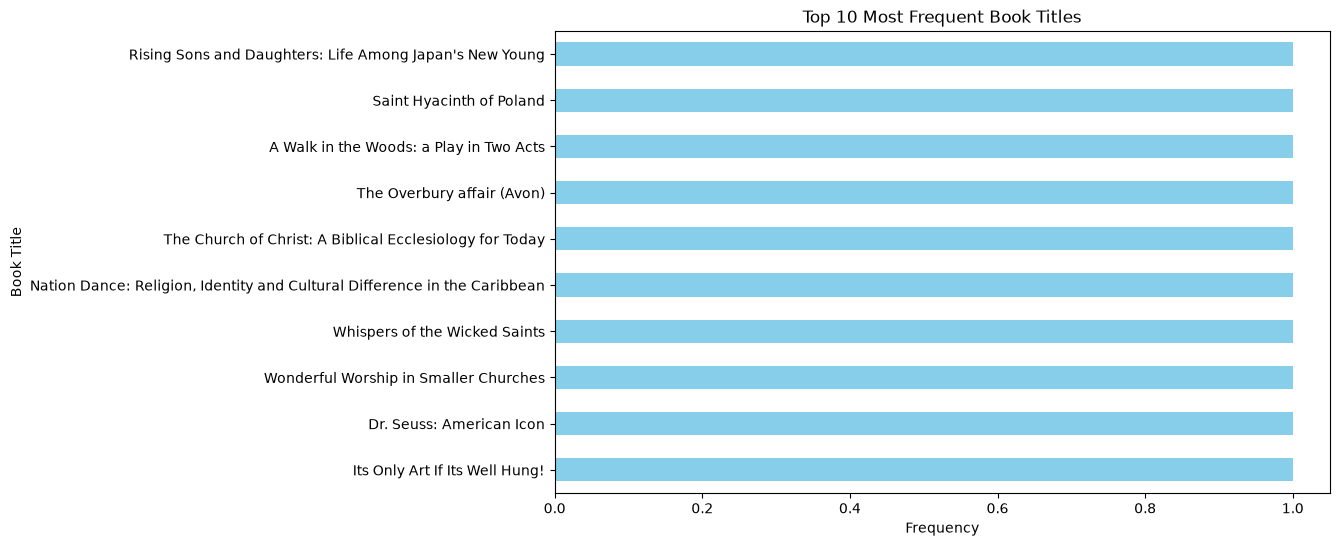

In [12]:
books.Title.value_counts().head(10).plot(kind="barh", figsize=(10, 6), color="skyblue")
plt.title("Top 10 Most Frequent Book Titles")
plt.xlabel("Frequency")
plt.ylabel("Book Title")
plt.show()

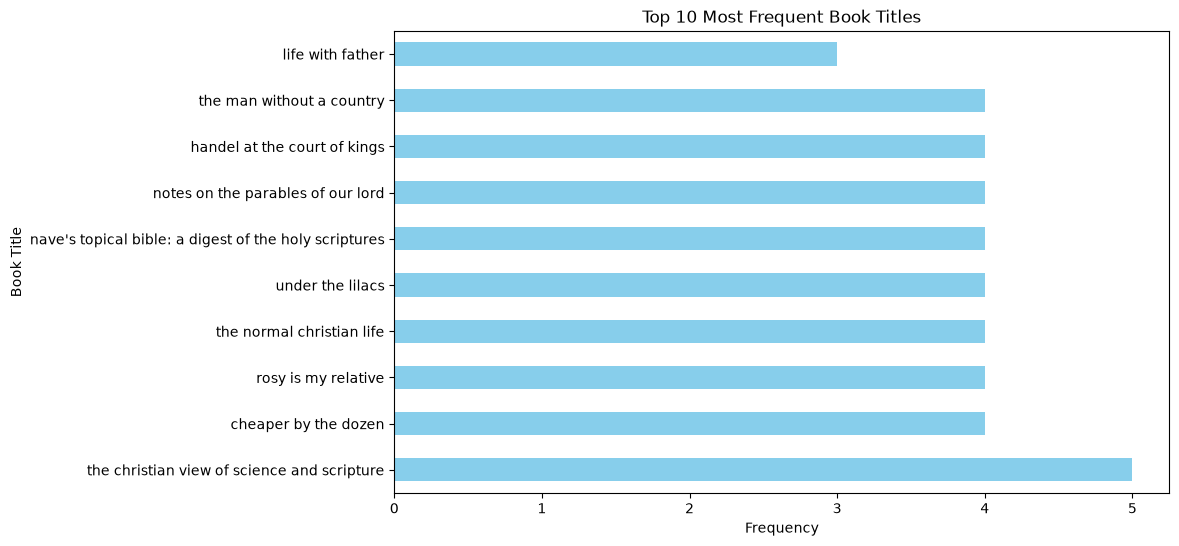

In [13]:

books.clean_title.value_counts().head(10).plot(kind="barh", figsize=(10, 6), color="skyblue")
plt.title("Top 10 Most Frequent Book Titles")
plt.xlabel("Frequency")
plt.ylabel("Book Title")
plt.show()


Повторы названий в каталоге могут размножить строки при объединении.
Для первого эксперимента оставляем первую строку каталога для каждого непустого
`clean_title`. Это упрощение: одноимённые книги могут иметь разных авторов,
поэтому соответствие описания не гарантировано.
Повторы названий в таблице оценок сами по себе нормальны: книгу оценивают разные люди.

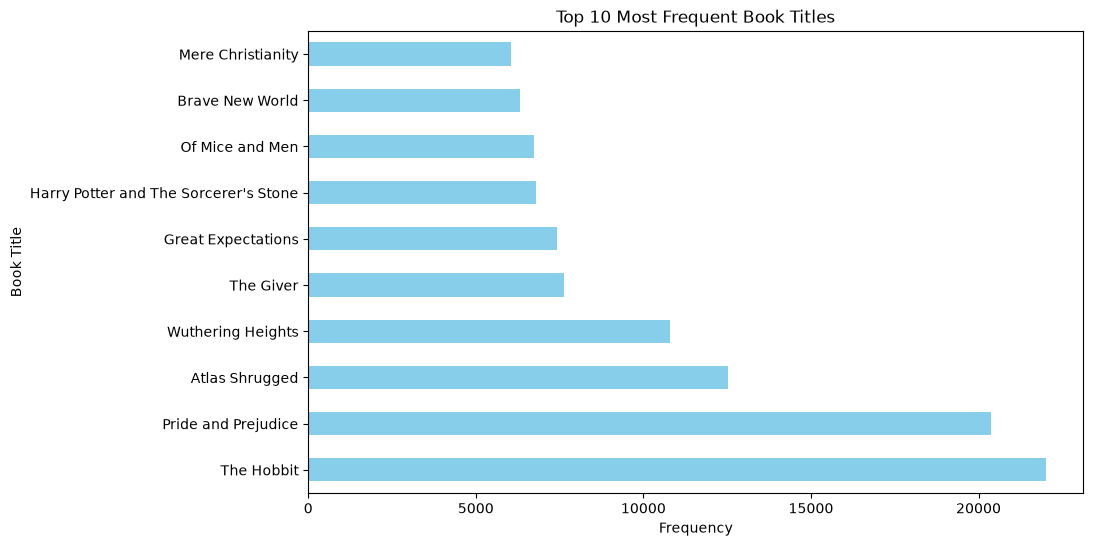

In [14]:
ratings.Title.value_counts().head(10).plot(kind="barh", figsize=(10, 6), color="skyblue")
plt.title("Top 10 Most Frequent Book Titles")
plt.xlabel("Frequency")
plt.ylabel("Book Title")
plt.show()

# Слияние

In [15]:
books_without_duplicates = (
    books[['clean_title', 'primary_genre', 'embedding_text']]
    .dropna(subset=['clean_title'])
    .drop_duplicates(subset=['clean_title'], keep='first')
)
assert books_without_duplicates['clean_title'].is_unique

In [16]:
merged_data = pd.merge(
    ratings_timed,
    books_without_duplicates,
    on='clean_title',
    how='left',
    validate='many_to_one',
    indicator=True,
)

# Слева одна строка на user–Id; справа не более одной строки на название.
assert len(merged_data) == len(ratings_timed), 'Merge изменил количество оценок'
assert not merged_data.duplicated(['User_id', 'Id']).any()

print(f'Оценок до / после merge: {len(ratings_timed)} / {len(merged_data)}')
print(f"Оценок без метаданных: {merged_data['_merge'].eq('left_only').sum()}")
print(f"Повторов User_id–Id: {merged_data.duplicated(['User_id', 'Id']).sum()}")
print(
    'Повторов User_id–clean_title (возможны разные издания):',
    merged_data.dropna(subset=['clean_title']).duplicated(['User_id', 'clean_title']).sum(),
)
merged_data = merged_data.drop(columns='_merge')

Оценок до / после merge: 2397596 / 2397596
Оценок без метаданных: 195
Повторов User_id–Id: 0
Повторов User_id–clean_title (возможны разные издания): 349809


In [17]:
n_users = merged_data['User_id'].nunique()
n_books = merged_data['Id'].nunique()
n_interactions = len(merged_data[['User_id', 'Id']].drop_duplicates())
if n_users == 0 or n_books == 0:
    raise ValueError('После подготовки не осталось пользователей или книг')
sparsity = 1.0 - n_interactions / (n_users * n_books)
print(f'Пользователей: {n_users}; книг (Id): {n_books}')
print(f'Разреженность матрицы User_id x Id: {sparsity:.5%}')

Пользователей: 1008965; книг (Id): 216022
Разреженность матрицы User_id x Id: 99.99890%


In [18]:
merged_data['text_len'] = merged_data['embedding_text'].str.len()
print(merged_data['text_len'].describe())

count    2.397401e+06
mean     6.253368e+02
std      6.285576e+02
min      1.000000e+01
25%      1.450000e+02
50%      3.590000e+02
75%      9.710000e+02
max      2.614200e+04
Name: text_len, dtype: float64


# Сплит

In [19]:
merged_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 2397596 entries, 0 to 2397595
Data columns (total 10 columns):
 #   Column          Dtype             
---  ------          -----             
 0   Id              string            
 1   Title           string            
 2   User_id         string            
 3   review/score    float32           
 4   review/time     int64             
 5   clean_title     string            
 6   event_time      datetime64[s, UTC]
 7   primary_genre   str               
 8   embedding_text  str               
 9   text_len        float64           
dtypes: datetime64[s, UTC](1), float32(1), float64(1), int64(1), str(2), string(4)
memory usage: 173.8 MB


2011-11-13 00:00:00
2012-11-24 00:00:00


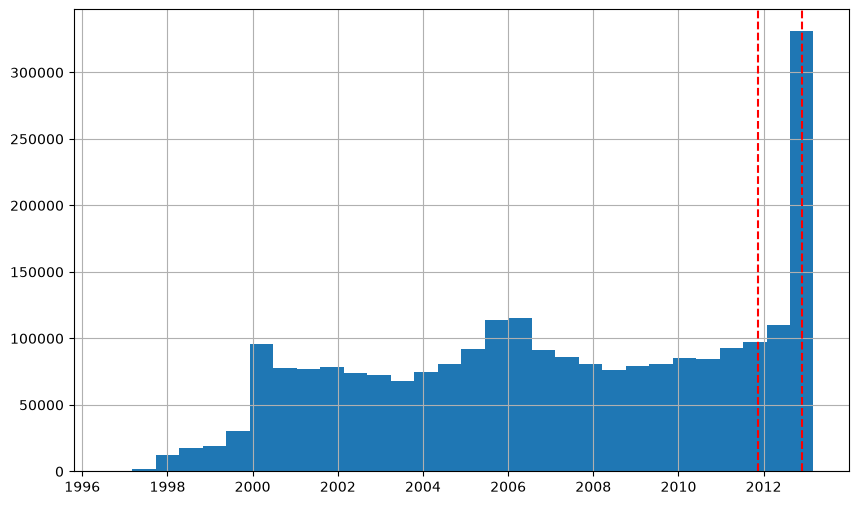

In [20]:
datetimes = merged_data['review/time']
pd.to_datetime(datetimes, unit='s').hist(bins=30, figsize=(10, 6))
boundaries = datetimes.quantile([0.8, 0.9]).values
for boundary in boundaries:
    plt.axvline(
        pd.to_datetime(boundary, unit='s'),
        color='red',
        linestyle='dashed'
    )
print(*pd.to_datetime(boundaries, unit='s'), sep='\n')

In [21]:
train, val, test = merged_data[merged_data['review/time'] <= boundaries[0]], \
                   merged_data[(merged_data['review/time'] > boundaries[0]) & (merged_data['review/time'] <= boundaries[1])], \
                   merged_data[merged_data['review/time'] > boundaries[1]]

In [22]:
pd.concat([
    pd.Series(
        [
            len(df),
            df['User_id'].nunique(),
            df['Id'].nunique(),
            (df['review/score'] >= 4).sum(),
            pd.to_datetime(df['review/time'], unit='s').min(),
            pd.to_datetime(df['review/time'], unit='s').max(),
        ],
        index=[
            'Число оценок',
            'Уникальные пользователи',
            'Уникальные Id',
            'Положительные оценки',
            'Минимальная дата',
            'Максимальная дата',
        ],
        name=name,
    )
    for name, df in zip(['Train', 'Validation', 'Test'], [train, val, test])
], axis=1)

,Train,Validation,Test
Число оценок,1918106,240524,238966
Уникальные пользователи,814332,117501,107603
Уникальные Id,204697,59650,46639
Положительные оценки,1521851,193234,204376
Минимальная дата,1996-08-17 00:00:00,2011-11-14 00:00:00,2012-11-25 00:00:00
Максимальная дата,2011-11-13 00:00:00,2012-11-24 00:00:00,2013-03-04 00:00:00


In [23]:
count_val_users_not_in_train = val[~val['User_id'].isin(train['User_id'])].shape[0]
count_val_books_not_in_train = val[~val['Id'].isin(train['Id'])].shape[0]

count_test_users_not_in_train = test[~test['User_id'].isin(train['User_id'])].shape[0]
count_test_books_not_in_train = test[~test['Id'].isin(train['Id'])].shape[0]
print(f"Validation: {count_val_users_not_in_train} users and {count_val_books_not_in_train} books not in train")
print(f"Test: {count_test_users_not_in_train} users and {count_test_books_not_in_train} books not in train")

Validation: 186336 users and 8448 books not in train
Test: 217844 users and 5659 books not in train
